# Stage 2 — Preprocess Coded-HT Projections

## Parameters


In [1]:
# --- paths ----------------------------------------------------------
# From config_steps15.conf, which holds every path for the holotomography scan.
# Edit that file, not this cell.
from holotomocupy.config import parse_args_coded_steps15
_cfg = parse_args_coded_steps15('config_steps15.conf')
WITH_CA = _cfg.path   # processed data for this sample


In [2]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import os
import cupy as cp
import cupyx.scipy.ndimage as ndimage
%matplotlib inline

# Input / output (single HDF5 — s2b appends pdata to the same file)
path_out  = WITH_CA + '/'
fname_in  = f'{WITH_CA}/codedHT.h5'   # written by s2a; s2b appends pdata here

# Processing chunk size (projections per batch)
chunk = 200   # number of projections per chunk. make sure that ntheta is divisible by chunk


## Load geometry, detector arrays, and signals

In [3]:
with h5py.File(fname_in, 'r') as f:
    # Geometry
    voxelsize               = float(f['/exchange/voxelsize'][0])
    magnification           = float(f['/exchange/magnification'][0])
    distance                = float(f['/exchange/distance'][0])
    z1                      = float(f['/exchange/z1'][0])
    z2                      = float(f['/exchange/z2'][0])
    energy                  = float(f['/exchange/energy'][0])
    wavelength              = float(f['/exchange/wavelength'][0])
    detector_pixelsize      = float(f['/exchange/detector_pixelsize'][0])
    focusToDetectorDistance = float(f['/exchange/focusdetectordistance'][0])

    # Motor positions
    theta_arr = f['/exchange/theta'][:]    # (ntheta,) deg
    spy_arr   = f['/exchange/spy'][:]      # (ntheta,) mm
    spz_arr   = f['/exchange/spz'][:]      # (ntheta,) mm

    # Dark and references
    dark_stack = f['/exchange/dark'][:].astype('float32')             # (ndark, ny, nx)
    ref0_stack = f['/exchange/data_white0'][:].astype('float32')      # (nref, ny, nx)  before
    ref1_stack = f['/exchange/data_white1'][:].astype('float32')      # (nref, ny, nx)  after

    # Per-frame detector signals: (ntheta, 3) — col 0=SR_Current [mA], col 1=BPM4, col 2=BPM5
    attrs  = f['/exchange/attrs'][:]       # (ntheta, 3)
    srcur  = attrs[:, 0]                  # SR_Current [mA]   (column 0)
    bpm4   = attrs[:, 1]                  # BPM4 diode signal  (column 1) — used by advisor

    # Pre-computed shifts (written by s2a)
    shifts = f['/exchange/shifts'][:]     # (ntheta, 2) px  pre-computed projection shifts

    # Data shape
    ntheta, ny, nx = f['/exchange/data'].shape

print(f'Data shape    : ({ntheta}, {ny}, {nx})')
print(f'voxelsize     : {voxelsize*1e9:.4f} nm')
print(f'magnification : {magnification:.2f}')
print(f'distance      : {distance*1e6:.4f} µm')
print(f'Dark stack    : {dark_stack.shape}')
print(f'Ref0 stack    : {ref0_stack.shape}')
print(f'Ref1 stack    : {ref1_stack.shape}')
print(f'srcur (SR_Current): [{srcur.min():.2f}, {srcur.max():.2f}] mA  '
      f'(drift={100*(srcur.max()-srcur.min())/srcur.mean():.2f}%)')
print(f'bpm4          : [{bpm4.min():.4f}, {bpm4.max():.4f}]')
print(f'shifts        : {shifts.shape}  row [{shifts[:,0].min():.2f}, {shifts[:,0].max():.2f}]')

Data shape    : (7200, 2048, 2048)
voxelsize     : 7.0005 nm
magnification : 433.90
distance      : 2943.2012 µm
Dark stack    : (20, 2048, 2048)
Ref0 stack    : (20, 2048, 2048)
Ref1 stack    : (20, 2048, 2048)
srcur (SR_Current): [193.58, 200.44] mA  (drift=3.49%)
bpm4          : [0.0011, 0.0012]
shifts        : (7200, 2)  row [-12.50, 12.50]


## Compute dark mean and reference means

In [4]:
dark_mean = dark_stack.mean(axis=0)   # (ny, nx)

def remove_outliers(data, dezinger, dezinger_threshold):
    """Replace zingers (hot pixels) with local median value.
    Matches advisor's step3_preprocessing definition exactly.
    Args:
        data:               (N, ny, nx) numpy float32 array
        dezinger:           median filter window size in pixels (e.g. 3 → 3×3 kernel)
        dezinger_threshold: relative deviation threshold (e.g. 0.8 → flag if |x-median|/median > 0.8)
    Returns numpy array of same shape with outliers replaced by local median.
    """
    res = data.copy()
    w = [dezinger, dezinger]
    for k in range(data.shape[0]):
        data0 = cp.array(data[k])
        fdata = ndimage.median_filter(data0, w)
        res[k] = np.where(
            np.abs(data0 - fdata) > fdata * dezinger_threshold, fdata, data0
        ).get()
    return res

def process_ref_stack(stack):
    """Apply the same corrections to reference frames as to projection data:
    dark subtract → clip → dead pixel patch → dezinger.
    Returns the full processed stack (not averaged)."""
    r = stack.copy()
    r -= dark_mean[np.newaxis]
    r[r < 0] = 0
    r[:, 1320//3:1320//3+25//3, 890//3:890//3+25//3] = \
        r[:, 1280//3:1280//3+25//3, 890//3:890//3+25//3]
    r = remove_outliers(r, 3, 0.8)
    return r

ref0_proc = process_ref_stack(ref0_stack)   # (nref, ny, nx) processed stack
ref1_proc = process_ref_stack(ref1_stack)   # (nref, ny, nx) processed stack

ref0_mean = ref0_proc.mean(axis=0)          # (ny, nx) averaged before-scan ref
ref1_mean = ref1_proc.mean(axis=0)          # (ny, nx) averaged after-scan ref

# Flat-field scalar (matches advisor's cnorm)
ref_norm_scalar = float(np.mean(ref0_mean))

# Normalised versions saved to HDF5 — matches advisor's pref0 / pref1
pref0 = ref0_mean / ref_norm_scalar         # (ny, nx)        ≈1.0 at open beam
pref1 = ref1_proc / ref_norm_scalar         # (nref, ny, nx)  per-frame normalised stack

# BPM4 reference value: first frame
bpm4_ref = float(bpm4[0])

print(f'dark_mean      : mean={dark_mean.mean():.1f}  std={dark_mean.std():.1f}')
print(f'ref0_mean      : mean={ref0_mean.mean():.1f}  min={ref0_mean.min():.6f}')
print(f'ref_norm_scalar: {ref_norm_scalar:.1f}')
print(f'pref0 shape    : {pref0.shape}   pref1 shape: {pref1.shape}')
print(f'bpm4_ref       : {bpm4_ref:.6f}')

ratio = ref1_mean.mean() / ref0_mean.mean()
print(f'Beam intensity ratio (end/start): {ratio:.4f}  (drift = {100*(ratio-1):.2f}%)')
bpm4_ratio = float(bpm4[-1]) / bpm4_ref
print(f'BPM4 ratio (end/start):           {bpm4_ratio:.4f}  (drift = {100*(bpm4_ratio-1):.2f}%)')

dark_mean      : mean=1197.9  std=123.2
ref0_mean      : mean=5682.8  min=354.749939
ref_norm_scalar: 5682.8
pref0 shape    : (2048, 2048)   pref1 shape: (20, 2048, 2048)
bpm4_ref       : 0.001221
Beam intensity ratio (end/start): 0.9523  (drift = -4.77%)
BPM4 ratio (end/start):           0.9585  (drift = -4.15%)


## Apply corrections (chunked)

In [5]:
with h5py.File(fname_in, 'a') as f:
    dset_in = f['/exchange/data']

    for key in ['/exchange/pdata', '/exchange/pref0', '/exchange/pref1']:
        if key in f:
            del f[key]

    dset_out = f.create_dataset(
        '/exchange/pdata',
        shape=(ntheta, ny, nx),
        dtype='float32',
        chunks=(1, ny, nx),
    )

    nchunks = int(np.ceil(ntheta / chunk))
    for ic in range(nchunks):
        st  = ic * chunk
        end = min(st + chunk, ntheta)

        raw = dset_in[st:end].astype('float32')

        # Step 1: dark subtraction 
        raw -= dark_mean[np.newaxis]

        # Step 2: clip to non-negative 
        raw[raw < 0] = 0

        # Step 3: dead pixel patch
        raw[:, 1320//3:1320//3+25//3, 890//3:890//3+25//3] = \
            raw[:, 1280//3:1280//3+25//3, 890//3:890//3+25//3]

        # Step 4: dezingering
        raw = remove_outliers(raw, 3, 0.8)

        # Step 5: flat-field normalisation (scalar) 
        raw /= ref_norm_scalar

        # Step 6: ring-current normalisation (BPM4)
        c_bpm4 = (bpm4[st:end] / bpm4_ref).astype('float32')
        raw /= c_bpm4[:, np.newaxis, np.newaxis]

        # Step 7: final clip
        raw = np.clip(raw, 0, None)
        dset_out[st:end] = raw

        if ic % 5 == 0:
            print(f'  chunk {ic+1:3d}/{nchunks}  frames {st:5d}–{end-1:5d}')

    # ── Save normalised reference arrays ─────────────
    f.create_dataset('/exchange/pref0', data=pref0)   # (ny, nx)         averaged normalised ref0
    f.create_dataset('/exchange/pref1', data=pref1)   # (nref, ny, nx)   per-frame normalised ref1 stack

print(f'\nSaved /exchange/pdata, /exchange/pref0, /exchange/pref1 → {fname_in}')


  chunk   1/36  frames     0–  199
  chunk   6/36  frames  1000– 1199
  chunk  11/36  frames  2000– 2199
  chunk  16/36  frames  3000– 3199
  chunk  21/36  frames  4000– 4199
  chunk  26/36  frames  5000– 5199
  chunk  31/36  frames  6000– 6199
  chunk  36/36  frames  7000– 7199

Saved /exchange/pdata, /exchange/pref0, /exchange/pref1 → /data3/cekmekci/AtomiumS2_coded/ht/codedHT.h5


## Visualise processed projections

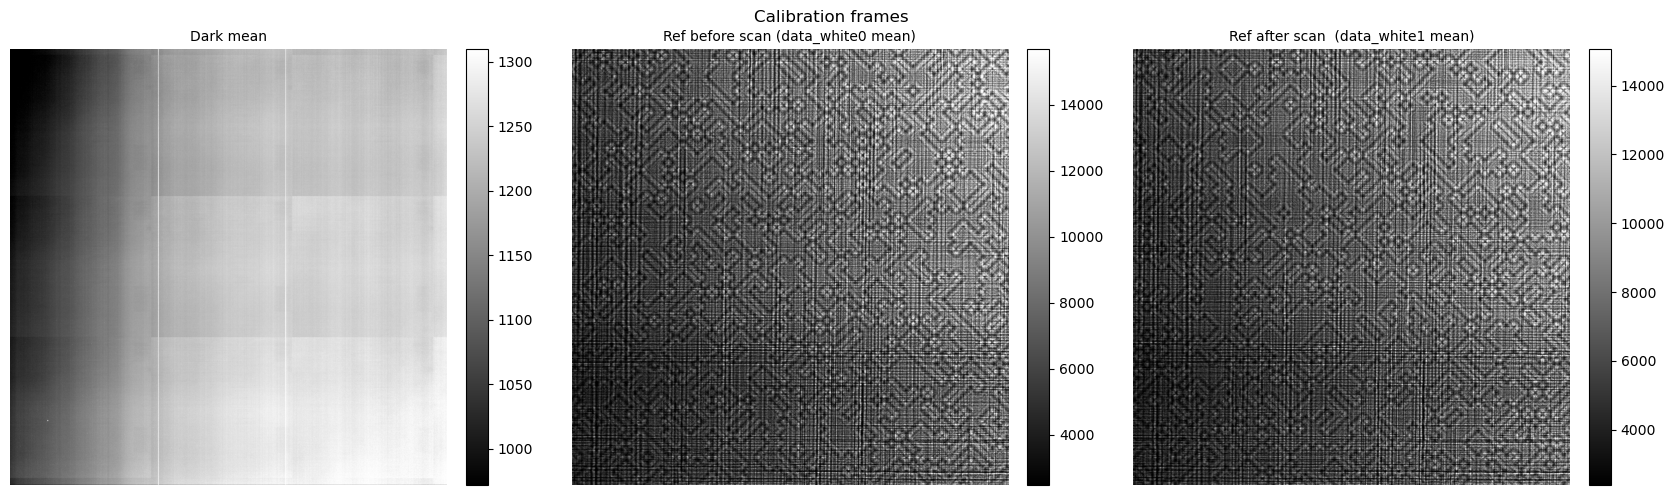

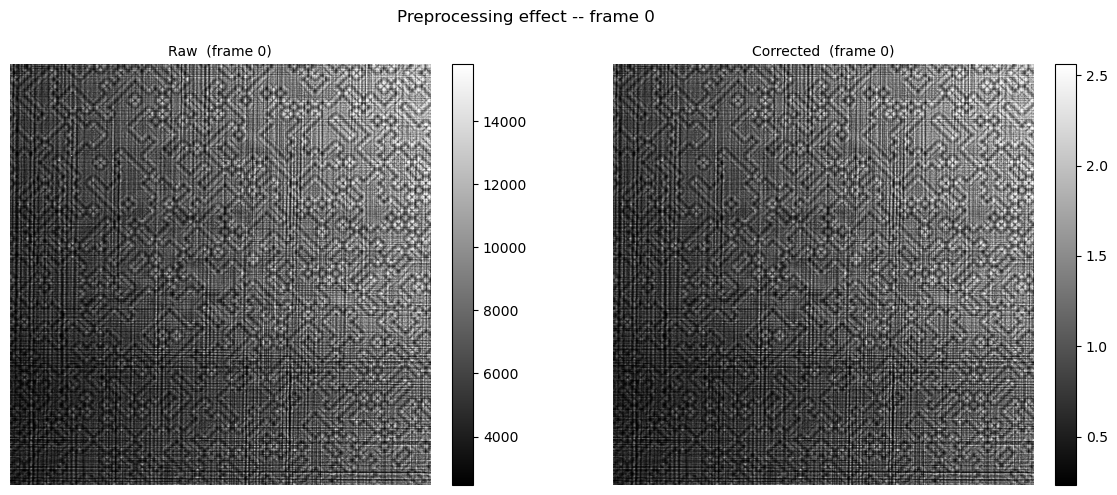

In [6]:
def ishow(ax, img, title, cmap='gray'):
    im = ax.imshow(img, cmap=cmap,
                   vmin=np.percentile(img, 1), vmax=np.percentile(img, 99))
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(title, fontsize=10)
    ax.axis('off')

with h5py.File(fname_in, 'r') as f:
    frame_raw  = f['/exchange/data'][0].astype('float32')
    frame_corr = f['/exchange/pdata'][0]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ishow(axes[0], dark_mean,             'Dark mean')
ishow(axes[1], ref0_mean + dark_mean, 'Ref before scan (data_white0 mean)')
ishow(axes[2], ref1_mean + dark_mean, 'Ref after scan  (data_white1 mean)')
plt.suptitle('Calibration frames', fontsize=12)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ishow(axes[0], frame_raw,  'Raw  (frame 0)')
ishow(axes[1], frame_corr, 'Corrected  (frame 0)')
plt.suptitle('Preprocessing effect -- frame 0', fontsize=12)
plt.tight_layout(); plt.show()